# ML Algorithms from Scratch

Демонстрация собственных реализаций ML-алгоритмов на NumPy.

In [10]:
import sys
from pathlib import Path

# Ищем корень проекта по наличию папки algorithms.
current_dir = Path.cwd().resolve()

project_root = next(
    (
        folder
        for folder in [current_dir, *current_dir.parents]
        if (folder / "algorithms" / "__init__.py").is_file()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Не найдена папка algorithms. "
        "Открой папку проекта в VS Code и перезапусти ноутбук."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from algorithms import (
    LinearRegression,
    LogisticRegression,
    GaussianNB,
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    RandomForestClassifier,
    GradientBoostingClassifier,
)

print("Корень проекта:", project_root)
print("Алгоритмы импортированы")

Корень проекта: /Users/alan/Documents/python/ml-algorithms-from-scratch
Алгоритмы импортированы


## Linear Regression

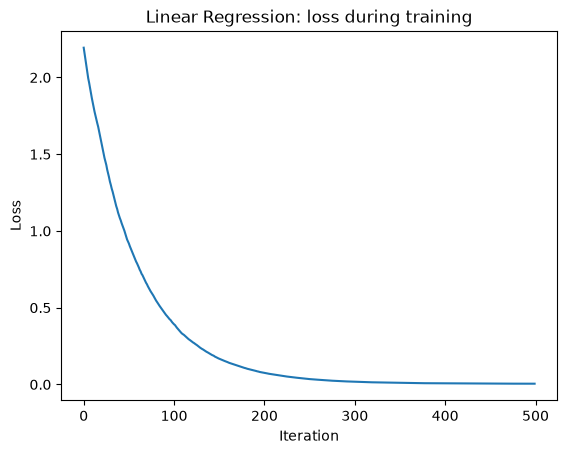

In [11]:
rng = np.random.default_rng(21)

X = rng.normal(size=(300, 3))
y = X @ np.array([2.0, -1.0, 0.5]) + rng.normal(scale=0.1, size=300)

model = LinearRegression(
    solver="mini_batch",
    max_iter=500,
    random_state=21,
)
model.fit(X, y)

plt.plot(model.loss_history_)
plt.title("Linear Regression: loss during training")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

## Logistic Regression

In [12]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

X_clf, y_clf = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=5,
    weights=[0.8, 0.2],
    random_state=21,
)

X_train, X_test, y_train, y_test = train_test_split(
    X_clf,
    y_clf,
    test_size=0.2,
    stratify=y_clf,
    random_state=21,
)

logreg = LogisticRegression(max_iter=1000, random_state=21)
logreg.fit(X_train, y_train)

probabilities = logreg.predict_proba(X_test)[:, 1]
print(f"Logistic Regression ROC-AUC: {roc_auc_score(y_test, probabilities):.4f}")

Logistic Regression ROC-AUC: 0.8703


## Gaussian Naive Bayes

In [13]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)

probabilities = gnb.predict_proba(X_test)[:, 1]
print(f"GaussianNB ROC-AUC: {roc_auc_score(y_test, probabilities):.4f}")

GaussianNB ROC-AUC: 0.8164


## Decision Tree Classifier

In [14]:
tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=21,
)
tree.fit(X_train, y_train)

probabilities = tree.predict_proba(X_test)[:, 1]
print(f"Decision Tree ROC-AUC: {roc_auc_score(y_test, probabilities):.4f}")

Decision Tree ROC-AUC: 0.7695


## Decision Tree Regressor

## Random Forest

In [15]:
forest = RandomForestClassifier(
    n_estimators=50,
    max_depth=5,
    random_state=21,
)
forest.fit(X_train, y_train)

probabilities = forest.predict_proba(X_test)[:, 1]
print(f"Random Forest ROC-AUC: {roc_auc_score(y_test, probabilities):.4f}")

Random Forest ROC-AUC: 0.8766


## Gradient Boosting

Gradient Boosting ROC-AUC: 0.8266


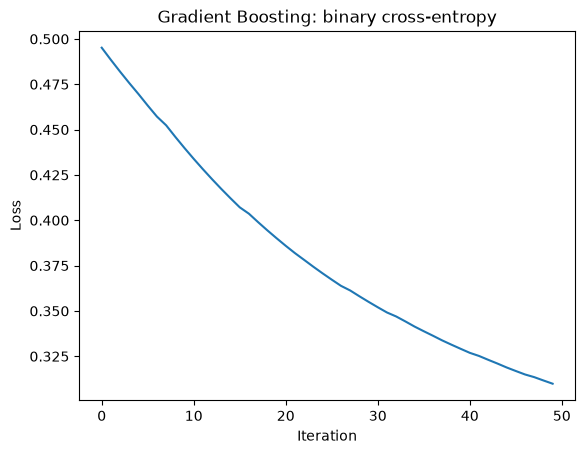

In [16]:
boosting = GradientBoostingClassifier(
    n_estimators=50,
    learning_rate=0.1,
    max_depth=3,
    random_state=21,
)
boosting.fit(X_train, y_train)

probabilities = boosting.predict_proba(X_test)[:, 1]
print(f"Gradient Boosting ROC-AUC: {roc_auc_score(y_test, probabilities):.4f}")

plt.plot(boosting.loss_history_)
plt.title("Gradient Boosting: binary cross-entropy")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

## Сравнение моделей

In [17]:
models = {
    "Logistic Regression": logreg,
    "GaussianNB": gnb,
    "Decision Tree": tree,
    "Random Forest": forest,
    "Gradient Boosting": boosting,
}

results = []

for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    results.append({
        "model": name,
        "roc_auc": roc_auc_score(y_test, probabilities),
    })

results

[{'model': 'Logistic Regression', 'roc_auc': 0.8703125},
 {'model': 'GaussianNB', 'roc_auc': 0.8164062500000001},
 {'model': 'Decision Tree', 'roc_auc': 0.76953125},
 {'model': 'Random Forest', 'roc_auc': 0.8765625},
 {'model': 'Gradient Boosting', 'roc_auc': 0.826640625}]

## Выводы

- Линейная регрессия демонстрирует аналитическое решение и оптимизацию градиентным спуском.
- Деревья строят нелинейные правила разбиения.
- Random Forest усредняет предсказания независимых деревьев.
- Gradient Boosting последовательно обучает деревья на остатках бинарной кросс-энтропии.